In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Lokasi dataset dari folder training
dataset_path = "../data/raw/faults.csv"

df = pd.read_csv(dataset_path)

print("Jumlah baris dan kolom:", df.shape)
print("\nDaftar kolom:")
print(df.columns.tolist())

print("\n5 baris pertama:")
display(df.head())

Jumlah baris dan kolom: (1941, 34)

Daftar kolom:
['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas', 'Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']

5 baris pertama:


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


### 1. Load Dataset

Pada tahap awal, dataset Steel Plates Faults dibaca menggunakan library Pandas.

Pemeriksaan dilakukan untuk mengetahui jumlah baris, jumlah kolom, nama-nama fitur, dan lima data pertama.

Dataset ini akan digunakan sebagai dasar pengembangan model supervised learning dan unsupervised learning. Oleh karena itu, struktur datanya perlu diperiksa sebelum dilakukan preprocessing.

In [2]:
# Pemeriksaan tipe data
print("=== TIPE DATA ===")
print(df.dtypes)

# Pemeriksaan missing value
print("\n=== MISSING VALUE ===")
print(df.isnull().sum())

print("\nTotal missing value:", df.isnull().sum().sum())

# Pemeriksaan duplikat
print("\n=== DATA DUPLIKAT ===")
print("Jumlah baris duplikat:", df.duplicated().sum())

# Statistik deskriptif
print("\n=== STATISTIK DESKRIPTIF ===")
display(df.describe())

=== TIPE DATA ===
X_Minimum                  int64
X_Maximum                  int64
Y_Minimum                  int64
Y_Maximum                  int64
Pixels_Areas               int64
X_Perimeter                int64
Y_Perimeter                int64
Sum_of_Luminosity          int64
Minimum_of_Luminosity      int64
Maximum_of_Luminosity      int64
Length_of_Conveyer         int64
TypeOfSteel_A300           int64
TypeOfSteel_A400           int64
Steel_Plate_Thickness      int64
Edges_Index              float64
Empty_Index              float64
Square_Index             float64
Outside_X_Index          float64
Edges_X_Index            float64
Edges_Y_Index            float64
Outside_Global_Index     float64
LogOfAreas               float64
Log_X_Index              float64
Log_Y_Index              float64
Orientation_Index        float64
Luminosity_Index         float64
SigmoidOfAreas           float64
Pastry                     int64
Z_Scratch                  int64
K_Scatch                 

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
count,1941.000000,1941.000000,1.941000e+03,1.941000e+03,1941.000000,1941.000000,1941.000000,1.941000e+03,1941.000000,1941.000000,...,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000
mean,571.136012,617.964451,1.650685e+06,1.650739e+06,1893.878413,111.855229,82.965997,2.063121e+05,84.548686,130.193715,...,0.083288,-0.131305,0.585420,0.081401,0.097888,0.201443,0.037094,0.028336,0.207110,0.346728
std,520.690671,497.627410,1.774578e+06,1.774590e+06,5168.459560,301.209187,426.482879,5.122936e+05,32.134276,18.690992,...,0.500868,0.148767,0.339452,0.273521,0.297239,0.401181,0.189042,0.165973,0.405339,0.476051
min,0.000000,4.000000,6.712000e+03,6.724000e+03,2.000000,2.000000,1.000000,2.500000e+02,0.000000,37.000000,...,-0.991000,-0.998900,0.119000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,51.000000,192.000000,4.712530e+05,4.712810e+05,84.000000,15.000000,13.000000,9.522000e+03,63.000000,124.000000,...,-0.333300,-0.195000,0.248200,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,435.000000,467.000000,1.204128e+06,1.204136e+06,174.000000,26.000000,25.000000,1.920200e+04,90.000000,127.000000,...,0.095200,-0.133000,0.506300,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1053.000000,1072.000000,2.183073e+06,2.183084e+06,822.000000,84.000000,83.000000,8.301100e+04,106.000000,140.000000,...,0.511600,-0.066600,0.999800,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,1705.000000,1713.000000,1.298766e+07,1.298769e+07,152655.000000,10449.000000,18152.000000,1.159141e+07,203.000000,253.000000,...,0.991700,0.642100,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### 2. Pemeriksaan Kualitas Data

Pada tahap ini dilakukan pemeriksaan tipe data, missing value, duplikat, dan statistik deskriptif pada dataset Steel Plates Faults.

Pemeriksaan tipe data bertujuan memastikan kolom dapat diolah menggunakan Python. Missing value diperiksa untuk mengetahui apakah terdapat data kosong yang perlu ditangani sebelum pemodelan.

Selain itu, pemeriksaan duplikat dilakukan untuk mengetahui apakah terdapat baris dengan isi yang sama. Statistik deskriptif digunakan untuk melihat nilai rata-rata, standar deviasi, nilai minimum, dan maksimum setiap fitur.

In [3]:
# Daftar 7 jenis cacat
fault_columns = [
    'Pastry',
    'Z_Scratch',
    'K_Scatch',
    'Stains',
    'Dirtiness',
    'Bumps',
    'Other_Faults'
]

# Ringkasan kualitas data
print("=== KUALITAS DATA ===")
print("Total missing value:", df.isnull().sum().sum())
print("Kolom non-numerik:")
print(df.select_dtypes(exclude='number').columns.tolist())

# Periksa nilai label
print("\n=== VALIDASI LABEL ===")
print("Semua label tersedia:", all(
    col in df.columns for col in fault_columns
))

print("Semua label bernilai 0 atau 1:",
      df[fault_columns].isin([0, 1]).all().all())

# Hitung berapa label aktif per baris
label_totals = df[fault_columns].sum(axis=1)

print("\nJumlah label aktif per baris:")
print(label_totals.value_counts().sort_index())

print("\nJumlah baris dengan label tidak valid:",
      (label_totals != 1).sum())

# Distribusi jenis cacat
print("\n=== DISTRIBUSI JENIS CACAT ===")
print(df[fault_columns].sum().sort_values(ascending=False))

=== KUALITAS DATA ===
Total missing value: 0
Kolom non-numerik:
[]

=== VALIDASI LABEL ===
Semua label tersedia: True
Semua label bernilai 0 atau 1: True

Jumlah label aktif per baris:
1    1941
Name: count, dtype: int64

Jumlah baris dengan label tidak valid: 0

=== DISTRIBUSI JENIS CACAT ===
Other_Faults    673
Bumps           402
K_Scatch        391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
dtype: int64


### 3. Pemeriksaan Label Jenis Cacat

Dataset Steel Plates Faults memiliki tujuh kolom label yang menunjukkan jenis cacat pada permukaan pelat baja.

Pemeriksaan dilakukan untuk memastikan setiap label menggunakan nilai biner 0 atau 1 dan setiap observasi hanya memiliki satu jenis cacat.

Selain itu, distribusi setiap jenis cacat dihitung untuk mengetahui apakah jumlah data antar kelas seimbang.

Hasil pemeriksaan ini digunakan sebagai dasar untuk mengubah tujuh kolom label menjadi satu kolom target bernama `fault_type`.

In [4]:
# Pastikan seluruh baris memiliki tepat satu label aktif
assert label_totals.eq(1).all(), "Ditemukan label tidak valid!"

# Membuat kolom target fault_type
df_clean = df.drop(columns=fault_columns).copy()

df_clean['fault_type'] = df[fault_columns].idxmax(axis=1)

# Memisahkan 27 fitur prediktor
feature_order = [
    col for col in df_clean.columns
    if col != 'fault_type'
]

# Validasi
assert len(feature_order) == 27
assert df_clean[feature_order].select_dtypes(
    exclude='number'
).empty is False if False else True

print("=== HASIL TRANSFORMASI DATA ===")
print("Ukuran dataset asli :", df.shape)
print("Ukuran dataset baru :", df_clean.shape)

print("\nJumlah fitur prediktor:", len(feature_order))

print("\nDaftar fitur:")
print(feature_order)

print("\nDistribusi target fault_type:")
print(df_clean['fault_type'].value_counts())

print("\n5 baris pertama dataset baru:")
display(df_clean.head())

=== HASIL TRANSFORMASI DATA ===
Ukuran dataset asli : (1941, 34)
Ukuran dataset baru : (1941, 28)

Jumlah fitur prediktor: 27

Daftar fitur:
['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas']

Distribusi target fault_type:
fault_type
Other_Faults    673
Bumps           402
K_Scatch        391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64

5 baris pertama dataset baru:


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,fault_type
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,Pastry
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,Pastry
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,Pastry
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,Pastry
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,Pastry


### 4. Transformasi Label Jenis Cacat

Pada tahap ini, tujuh kolom label biner diubah menjadi satu kolom target bernama `fault_type`.

Proses transformasi dilakukan menggunakan fungsi `idxmax()` setelah dipastikan bahwa setiap baris memiliki tepat satu label aktif.

Ketujuh kolom label asli dihapus dari dataset hasil transformasi sehingga tersisa 27 fitur prediktor dan satu kolom target.

Pemisahan ini diperlukan agar informasi jenis cacat tidak ikut digunakan sebagai fitur masukan model. Dataset hasil transformasi nantinya menjadi data bersama untuk pengembangan supervised learning dan unsupervised learning.

In [5]:
from pathlib import Path

# Menentukan lokasi output berdasarkan file dataset asli
raw_path = Path(dataset_path).resolve()
output_path = raw_path.parent.parent / "processed" / "steel_faults_clean.csv"

# Membuat folder jika belum ada
output_path.parent.mkdir(parents=True, exist_ok=True)

# Validasi sebelum menyimpan
assert len(feature_order) == 27
assert all(
    pd.api.types.is_numeric_dtype(df_clean[col])
    for col in feature_order
), "Ada fitur yang bukan numerik!"

assert not set(fault_columns).intersection(feature_order)
assert df_clean['fault_type'].notna().all()

# Simpan CSV tanpa kolom indeks tambahan
df_clean.to_csv(output_path, index=False)

# Baca ulang untuk memastikan file berhasil disimpan
df_saved = pd.read_csv(output_path)

print("=== HASIL PENYIMPANAN DATASET ===")
print("Lokasi file:", output_path)
print("File tersedia:", output_path.exists())
print("Ukuran dataset:", df_saved.shape)
print("Jumlah fitur:", len(feature_order))
print("Jumlah kelas:", df_saved['fault_type'].nunique())

# Validasi data tersimpan
assert df_saved.shape == (1941, 28)
assert df_saved.columns.tolist() == feature_order + ['fault_type']

print("\nDataset berhasil disimpan dan divalidasi!")

=== HASIL PENYIMPANAN DATASET ===
Lokasi file: C:\vs code\smart-ml-kelompok-3\The-Bujang-Kelompok-3\data\processed\steel_faults_clean.csv
File tersedia: True
Ukuran dataset: (1941, 28)
Jumlah fitur: 27
Jumlah kelas: 7

Dataset berhasil disimpan dan divalidasi!


### 5. Menyimpan Dataset Hasil Preprocessing

Setelah proses transformasi label selesai, dataset disimpan dalam format CSV dengan nama `steel_faults_clean.csv`.

Dataset hasil preprocessing terdiri dari 27 fitur prediktor numerik dan satu kolom target `fault_type` yang menunjukkan jenis cacat pada pelat baja.

Data disimpan tanpa mengubah skala fitur aslinya. Proses scaling akan dilakukan oleh masing-masing model pada tahap pelatihan agar tidak terjadi data leakage.

File hasil preprocessing nantinya digunakan bersama oleh anggota kelompok yang bertanggung jawab mengembangkan model supervised learning dan unsupervised learning.

In [6]:
import json

# Menentukan lokasi root repository
repo_root = output_path.parent.parent.parent

schema_path = repo_root / "config" / "feature_schema.json"
schema_path.parent.mkdir(parents=True, exist_ok=True)

# Nilai median dari dataset sebagai default referensi form
defaults = {
    col: float(df_clean[col].median())
    for col in feature_order
}

# Membuat schema
feature_schema = {
    "feature_order": feature_order,
    "target_column": "fault_type",
    "fault_classes": fault_columns,
    "defaults": defaults
}

# Menyimpan JSON
with open(schema_path, "w", encoding="utf-8") as f:
    json.dump(feature_schema, f, indent=4)

# Membaca ulang untuk validasi
with open(schema_path, "r", encoding="utf-8") as f:
    schema_saved = json.load(f)

assert len(schema_saved["feature_order"]) == 27
assert len(schema_saved["fault_classes"]) == 7
assert schema_saved["target_column"] == "fault_type"
assert list(schema_saved["defaults"]) == feature_order

print("=== HASIL FEATURE SCHEMA ===")
print("Lokasi file:", schema_path)
print("File tersedia:", schema_path.exists())
print("Jumlah fitur:", len(schema_saved["feature_order"]))
print("Jumlah kelas:", len(schema_saved["fault_classes"]))
print("Target:", schema_saved["target_column"])

print("\nContoh 5 nilai default:")
for col in feature_order[:5]:
    print(f"{col}: {defaults[col]}")

print("\nFeature schema berhasil dibuat!")

=== HASIL FEATURE SCHEMA ===
Lokasi file: C:\vs code\smart-ml-kelompok-3\The-Bujang-Kelompok-3\config\feature_schema.json
File tersedia: True
Jumlah fitur: 27
Jumlah kelas: 7
Target: fault_type

Contoh 5 nilai default:
X_Minimum: 435.0
X_Maximum: 467.0
Y_Minimum: 1204128.0
Y_Maximum: 1204136.0
Pixels_Areas: 174.0

Feature schema berhasil dibuat!


### 6. Pembuatan Feature Schema

Pada tahap ini dibuat file `feature_schema.json` yang digunakan untuk menyimpan struktur fitur dataset Steel Plates Faults.

File tersebut berisi urutan 27 fitur prediktor, nama kolom target `fault_type`, tujuh jenis cacat, serta nilai default setiap fitur yang dihitung menggunakan median dataset.

Feature schema diperlukan agar semua anggota kelompok menggunakan struktur input yang konsisten ketika mengembangkan model supervised learning, unsupervised learning, dan aplikasi web.

Nilai default digunakan sebagai referensi pengisian form, sedangkan preprocessing untuk pelatihan model dilakukan secara terpisah agar tidak terjadi data leakage.

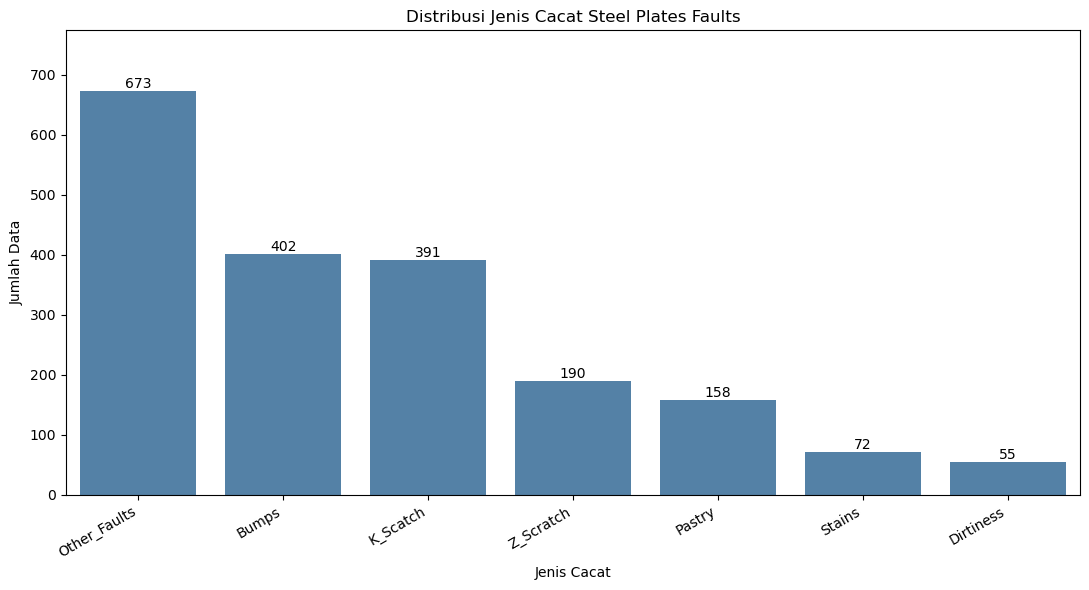

=== DISTRIBUSI JENIS CACAT ===


,Jumlah Data,Persentase (%)
fault_type,,
Other_Faults,673,34.67
Bumps,402,20.71
K_Scatch,391,20.14
Z_Scratch,190,9.79
Pastry,158,8.14
Stains,72,3.71
Dirtiness,55,2.83


In [7]:
# Menghitung jumlah setiap jenis cacat
fault_counts = df_clean['fault_type'].value_counts()

# Menghitung persentase
fault_percentages = (
    df_clean['fault_type'].value_counts(normalize=True) * 100
)

# Visualisasi
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=fault_counts.index,
    y=fault_counts.values,
    color='steelblue'
)

# Menampilkan jumlah data di atas batang
for i, count in enumerate(fault_counts.values):
    ax.text(
        i,
        count + 5,
        str(count),
        ha='center',
        fontsize=10
    )

plt.title('Distribusi Jenis Cacat Steel Plates Faults')
plt.xlabel('Jenis Cacat')
plt.ylabel('Jumlah Data')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, fault_counts.max() * 1.15)
plt.tight_layout()
plt.show()

# Ringkasan distribusi
print("=== DISTRIBUSI JENIS CACAT ===")

distribution_df = pd.DataFrame({
    'Jumlah Data': fault_counts,
    'Persentase (%)': fault_percentages.round(2)
})

display(distribution_df)

### 7. Visualisasi Distribusi Jenis Cacat

Pada tahap ini dilakukan visualisasi distribusi tujuh jenis cacat pada dataset Steel Plates Faults menggunakan grafik batang.

Grafik digunakan untuk membandingkan jumlah data pada setiap kategori, yaitu Pastry, Z_Scratch, K_Scatch, Stains, Dirtiness, Bumps, dan Other_Faults.

Berdasarkan pemeriksaan sebelumnya, Other_Faults merupakan kelas dengan jumlah data terbanyak, yaitu 673 observasi. Sementara itu, Dirtiness memiliki jumlah data paling sedikit, yaitu 55 observasi.

Perbedaan jumlah data tersebut menunjukkan adanya ketidakseimbangan kelas (class imbalance). Kondisi ini perlu diperhatikan pada tahap supervised learning karena model berpotensi lebih mudah mempelajari kelas yang jumlah datanya banyak dibandingkan kelas minoritas.

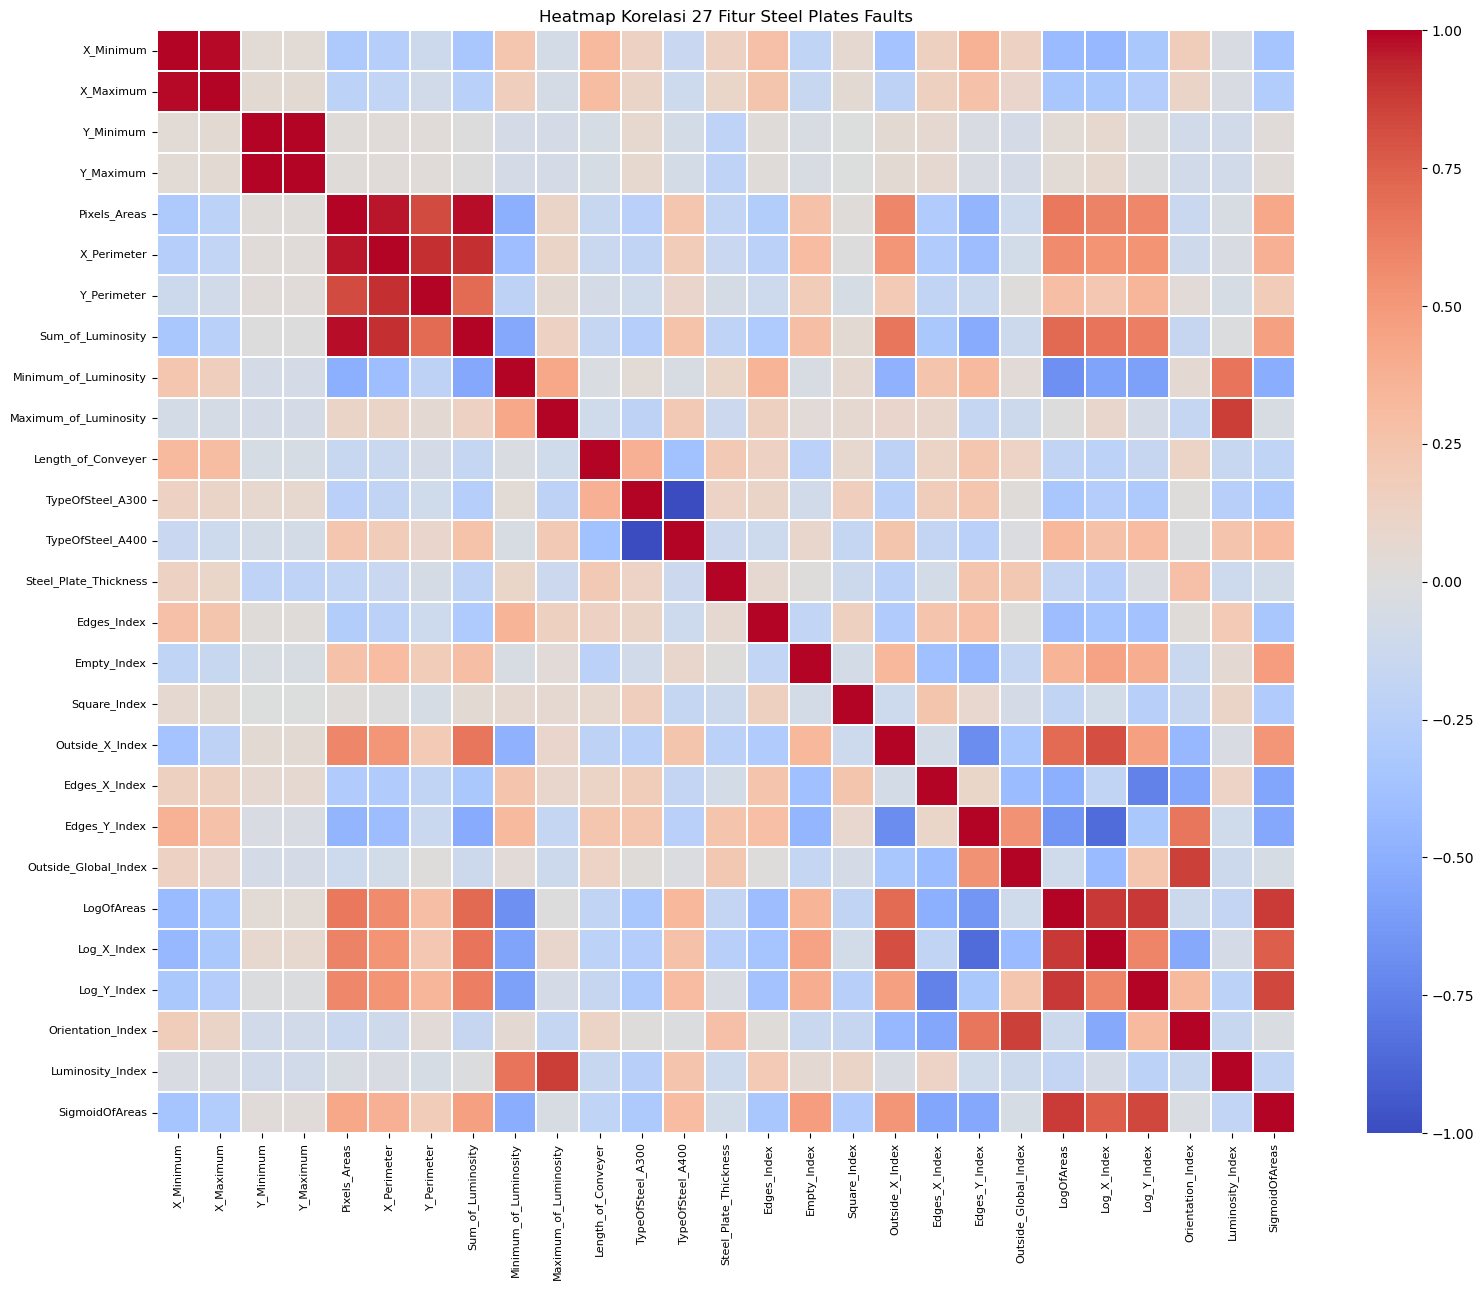

=== 10 PASANGAN FITUR DENGAN KORELASI TERKUAT ===


,Fitur 1,Fitur 2,Korelasi,Absolut Korelasi
231,TypeOfSteel_A300,TypeOfSteel_A400,-1.000000,1.000000
51,Y_Minimum,Y_Maximum,1.000000,1.000000
0,X_Minimum,X_Maximum,0.988314,0.988314
100,Pixels_Areas,Sum_of_Luminosity,0.978952,0.978952
98,Pixels_Areas,X_Perimeter,0.966644,0.966644
121,X_Perimeter,Sum_of_Luminosity,0.912956,0.912956
120,X_Perimeter,Y_Perimeter,0.912436,0.912436
336,LogOfAreas,Log_X_Index,0.888919,0.888919
337,LogOfAreas,Log_Y_Index,0.882974,0.882974
340,LogOfAreas,SigmoidOfAreas,0.877768,0.877768


In [8]:
# Mengambil 27 fitur prediktor tanpa kolom target
X_features = df_clean[feature_order]

# Menghitung korelasi
correlation_matrix = X_features.corr()

# Membuat heatmap
plt.figure(figsize=(16, 13))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.2
)

plt.title('Heatmap Korelasi 27 Fitur Steel Plates Faults')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

# Mencari pasangan fitur dengan korelasi tertinggi
mask = np.triu(
    np.ones(correlation_matrix.shape, dtype=bool),
    k=1
)

correlation_pairs = (
    correlation_matrix
    .where(mask)
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    'Fitur 1',
    'Fitur 2',
    'Korelasi'
]

correlation_pairs['Absolut Korelasi'] = (
    correlation_pairs['Korelasi'].abs()
)

top_correlations = correlation_pairs.sort_values(
    'Absolut Korelasi',
    ascending=False
).head(10)

print("=== 10 PASANGAN FITUR DENGAN KORELASI TERKUAT ===")
display(top_correlations)

### 8. Analisis Korelasi Antarfitur

Pada tahap ini dilakukan analisis korelasi terhadap 27 fitur prediktor menggunakan heatmap.

Korelasi digunakan untuk mengetahui hubungan linear antara dua fitur. Nilainya berada pada rentang -1 sampai 1. Nilai mendekati 1 menunjukkan hubungan positif yang kuat, sedangkan nilai mendekati -1 menunjukkan hubungan negatif yang kuat.

Selain heatmap, ditampilkan sepuluh pasangan fitur dengan nilai korelasi absolut tertinggi.

Analisis ini membantu mengetahui apakah terdapat beberapa fitur yang memberikan informasi serupa. Kolom target fault_type tidak disertakan karena analisis dilakukan hanya pada fitur prediktor.

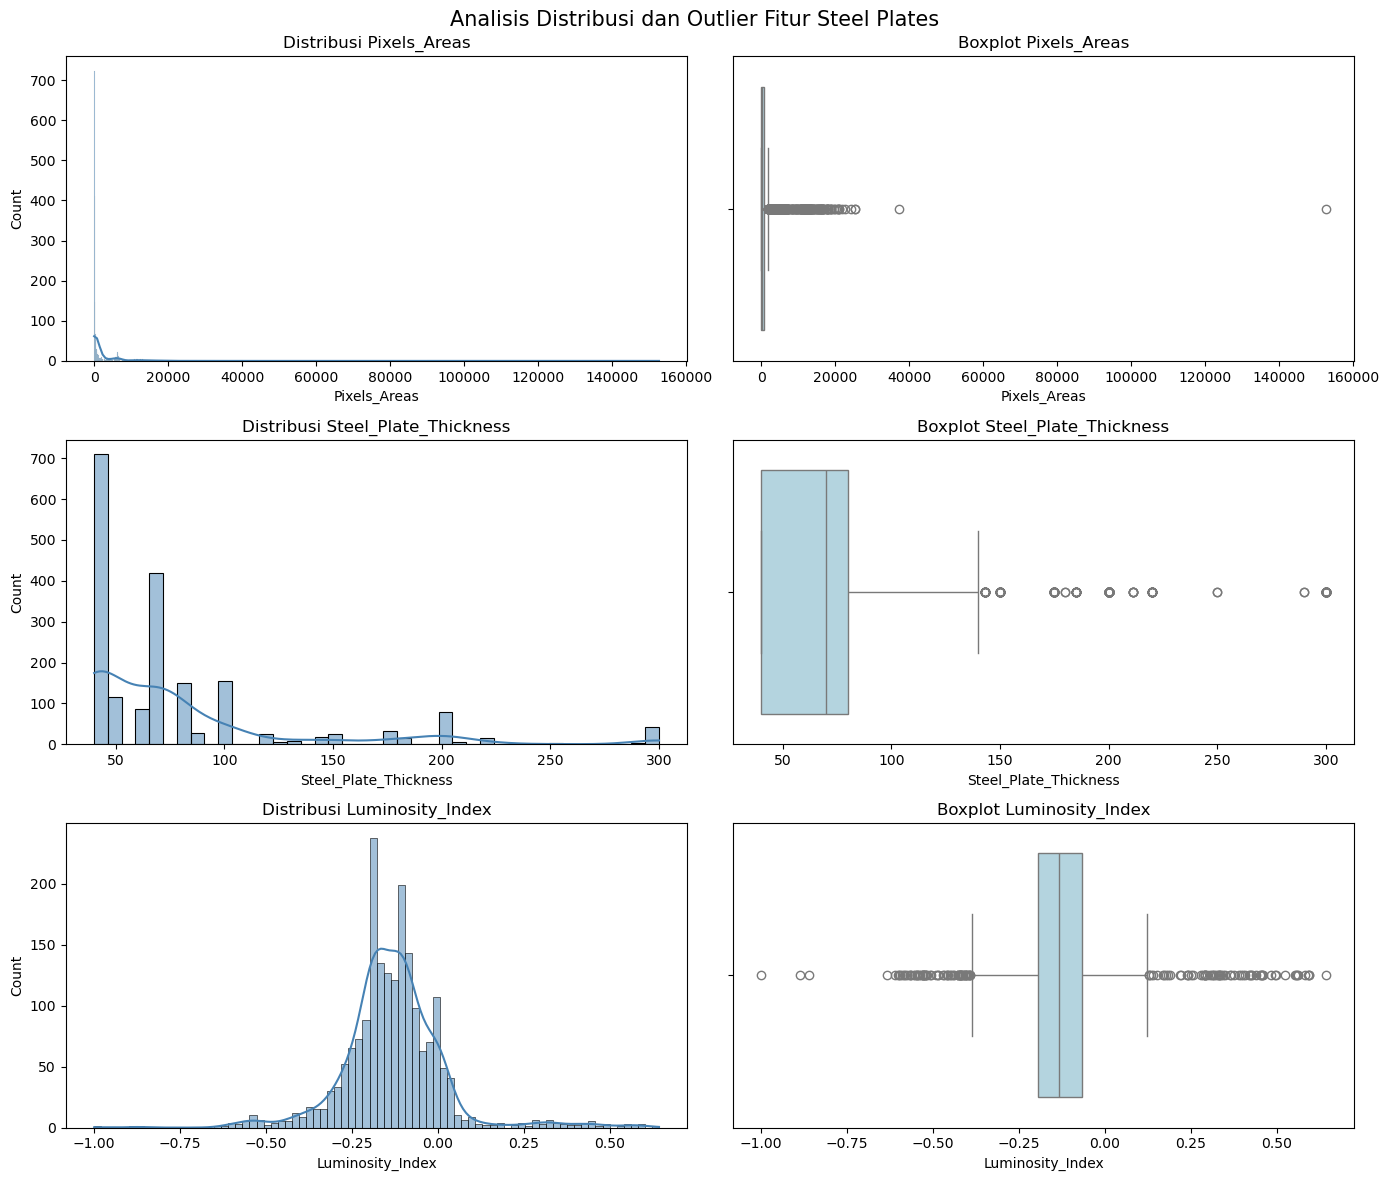

=== STATISTIK FITUR TERPILIH ===


,Pixels_Areas,Steel_Plate_Thickness,Luminosity_Index
count,1941.000000,1941.000000,1941.000000
mean,1893.878413,78.737764,-0.131305
std,5168.459560,55.086032,0.148767
min,2.000000,40.000000,-0.998900
25%,84.000000,40.000000,-0.195000
50%,174.000000,70.000000,-0.133000
75%,822.000000,80.000000,-0.066600
max,152655.000000,300.000000,0.642100


In [9]:

# Memilih tiga fitur untuk dianalisis
selected_features = [
    'Pixels_Areas',
    'Steel_Plate_Thickness',
    'Luminosity_Index'
]

# Membuat histogram dan boxplot
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for i, feature in enumerate(selected_features):

    # Histogram distribusi
    sns.histplot(
        data=df_clean,
        x=feature,
        kde=True,
        color='steelblue',
        ax=axes[i, 0]
    )

    axes[i, 0].set_title(
        f'Distribusi {feature}'
    )

    # Boxplot untuk melihat nilai ekstrem
    sns.boxplot(
        data=df_clean,
        x=feature,
        color='lightblue',
        ax=axes[i, 1]
    )

    axes[i, 1].set_title(
        f'Boxplot {feature}'
    )

plt.suptitle(
    'Analisis Distribusi dan Outlier Fitur Steel Plates',
    fontsize=15
)

plt.tight_layout()
plt.show()

# Statistik tiga fitur
print("=== STATISTIK FITUR TERPILIH ===")
display(df_clean[selected_features].describe())



### 9. Analisis Distribusi dan Outlier Fitur

Visualisasi dilakukan terhadap fitur Pixels_Areas, Steel_Plate_Thickness, dan Luminosity_Index menggunakan histogram dan boxplot.

Berdasarkan hasil pengujian, Pixels_Areas memiliki distribusi yang sangat miring ke kanan. Hal ini terlihat dari rata-rata sebesar 1.893,88 yang jauh lebih tinggi dibandingkan median 174. Nilai maksimumnya mencapai 152.655, sehingga terdapat beberapa data dengan luas cacat yang jauh lebih besar daripada sebagian besar observasi.

Pada Steel_Plate_Thickness, nilai ketebalan berada pada rentang 40 hingga 300 dengan median 70. Sebagian besar data memiliki ketebalan relatif kecil, sedangkan beberapa observasi mempunyai ketebalan yang lebih tinggi.

Sementara itu, Luminosity_Index memiliki rata-rata -0,1313 dan median -0,1330. Distribusinya lebih terkonsentrasi di sekitar nilai negatif kecil, meskipun masih ditemukan beberapa nilai ekstrem.

Dari ketiga fitur tersebut, dapat disimpulkan bahwa dataset memiliki karakteristik distribusi yang berbeda dan mengandung sejumlah nilai ekstrem. Data tersebut tidak langsung dihapus karena mungkin merupakan informasi penting untuk mengenali jenis cacat pelat baja.
